In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("battery_cycle_level_dataset_CLEAN_FINAL.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1415, 7)


,battery_id,cycle,voltage,temperature,capacity,soh,rul
0,B0005,1,3.532781,32.536891,1.861976,1.000000,167
1,B0005,2,3.542968,32.643595,1.851862,0.994568,166
2,B0005,3,3.553056,32.522526,1.840808,0.988631,165
3,B0005,4,3.545849,32.492083,1.850058,0.993599,164
4,B0005,5,3.544456,32.368612,1.849432,0.993263,163


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nNumber of Unique Batteries:")
print(df["battery_id"].nunique())

print("\nStatistical Summary:")
df.describe()

Column Names:
['battery_id', 'cycle', 'voltage', 'temperature', 'capacity', 'soh', 'rul']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1415 entries, 0 to 1414
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   battery_id   1415 non-null   str    
 1   cycle        1415 non-null   int64  
 2   voltage      1415 non-null   float64
 3   temperature  1415 non-null   float64
 4   capacity     1415 non-null   float64
 5   soh          1415 non-null   float64
 6   rul          1415 non-null   int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 77.5 KB

Missing Values:
battery_id     0
cycle          0
voltage        0
temperature    0
capacity       0
soh            0
rul            0
dtype: int64

Number of Unique Batteries:
34

Statistical Summary:


,cycle,voltage,temperature,capacity,soh,rul
count,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000
mean,55.389399,3.420612,26.589773,1.501191,0.849014,54.175972
std,42.728497,0.166460,13.196045,0.316995,0.119219,43.709204
min,1.000000,2.530010,7.684550,0.520105,0.604449,0.000000
25%,21.000000,3.387078,9.555186,1.321640,0.750777,16.500000
50%,43.000000,3.452596,31.139259,1.504115,0.850350,43.000000
75%,87.000000,3.507450,32.753400,1.709022,0.961174,86.000000
max,168.000000,3.753027,54.997372,2.498996,1.048527,167.000000


In [4]:
print("Data Types:")
print(df.dtypes)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Batteries:", df["battery_id"].nunique())

print("\nCycles per Battery:")
print(df.groupby("battery_id")["cycle"].count().describe())

Data Types:
battery_id         str
cycle            int64
voltage        float64
temperature    float64
capacity       float64
soh            float64
rul              int64
dtype: object

Duplicate Rows: 0

Unique Batteries: 34

Cycles per Battery:
count     34.000000
mean      41.617647
std       50.542520
min        1.000000
25%        2.000000
50%       23.000000
75%       68.250000
max      168.000000
Name: cycle, dtype: float64


In [5]:
print("SOH Summary:")
print(df["soh"].describe())

print("\nMinimum SOH:", df["soh"].min())
print("Maximum SOH:", df["soh"].max())

print("\nNumber of Unique SOH Values:", df["soh"].nunique())

SOH Summary:
count    1415.000000
mean        0.849014
std         0.119219
min         0.604449
25%         0.750777
50%         0.850350
75%         0.961174
max         1.048527
Name: soh, dtype: float64

Minimum SOH: 0.604448676087178
Maximum SOH: 1.0485271606255615

Number of Unique SOH Values: 1382


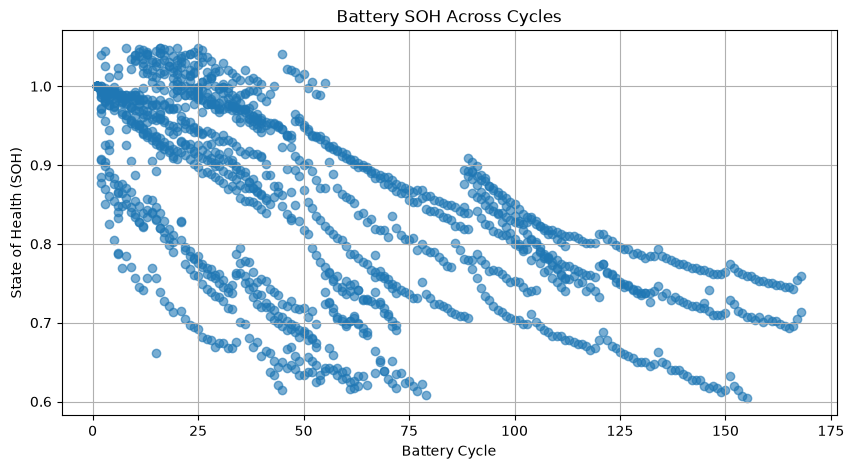

In [6]:
plt.figure(figsize=(10, 5))

plt.scatter(df["cycle"], df["soh"], alpha=0.6)

plt.xlabel("Battery Cycle")
plt.ylabel("State of Health (SOH)")
plt.title("Battery SOH Across Cycles")

plt.grid(True)
plt.show()

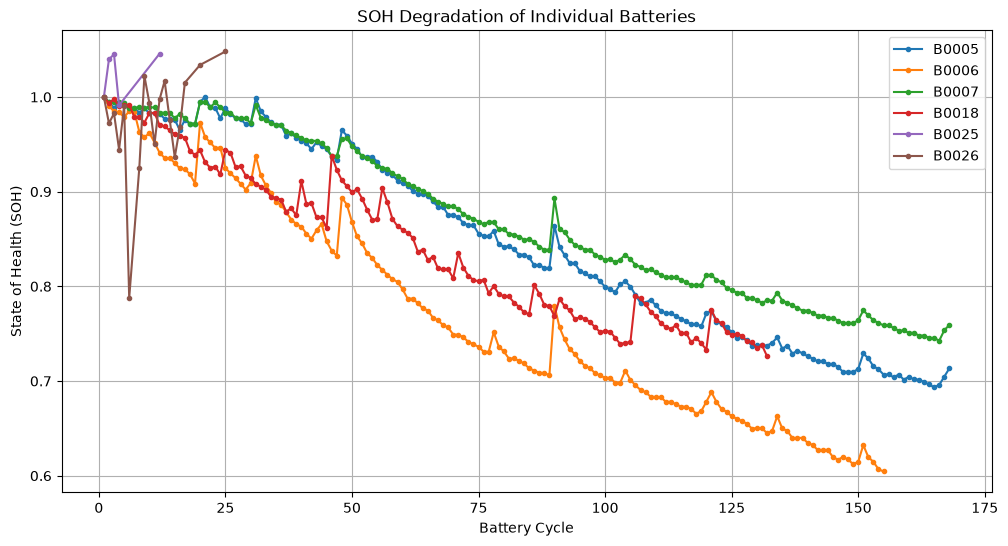

In [7]:
plt.figure(figsize=(12, 6))

for battery in df["battery_id"].unique()[:6]:
    battery_data = df[df["battery_id"] == battery]

    plt.plot(
        battery_data["cycle"],
        battery_data["soh"],
        marker="o",
        markersize=3,
        label=battery
    )

plt.xlabel("Battery Cycle")
plt.ylabel("State of Health (SOH)")
plt.title("SOH Degradation of Individual Batteries")

plt.legend()
plt.grid(True)
plt.show()

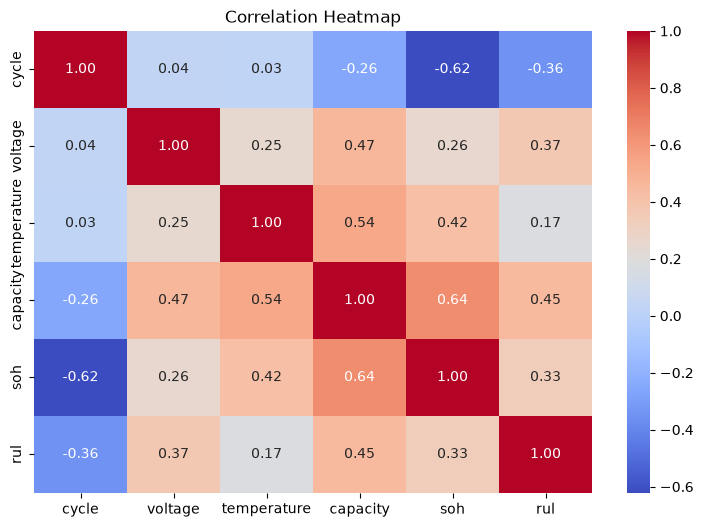

In [8]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

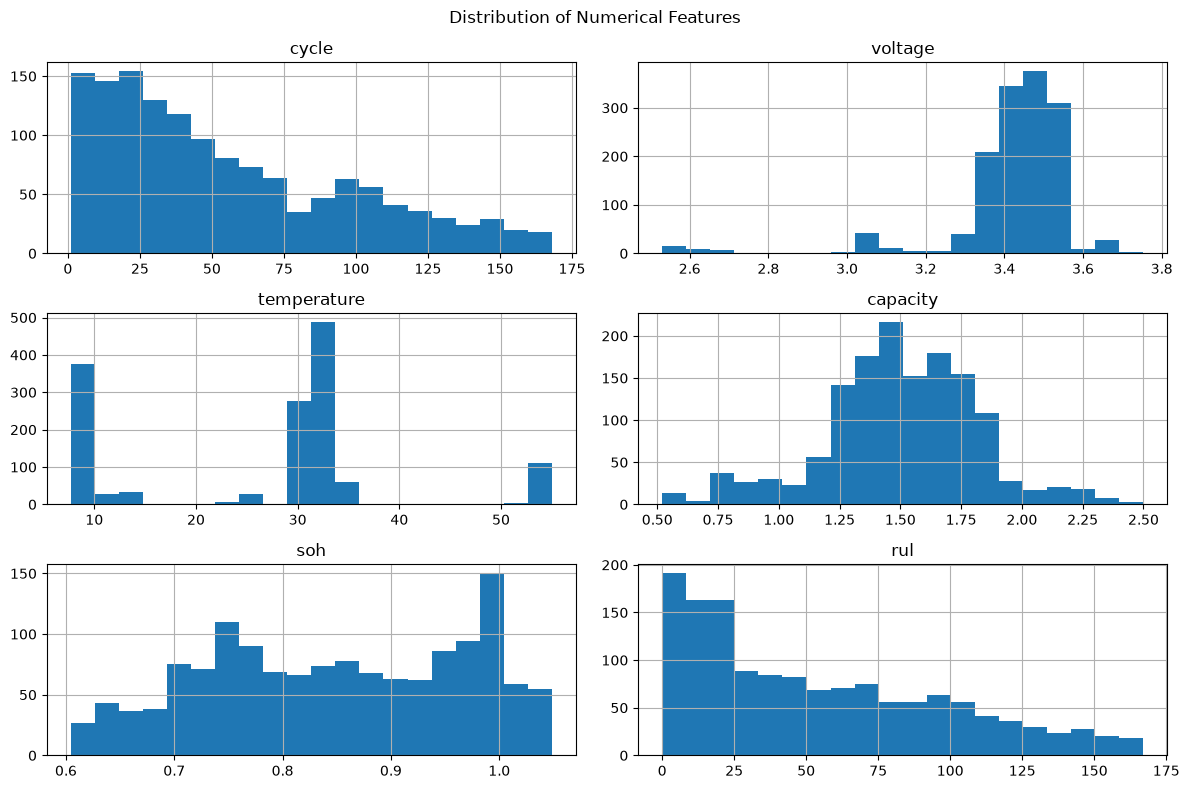

In [9]:
df[["cycle", "voltage", "temperature", "capacity", "soh", "rul"]].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [10]:
print("Dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
print(df.describe().round(4))

Dataset shape: (1415, 7)

Duplicate rows: 0

Missing values:
battery_id     0
cycle          0
voltage        0
temperature    0
capacity       0
soh            0
rul            0
dtype: int64

Data types:
battery_id         str
cycle            int64
voltage        float64
temperature    float64
capacity       float64
soh            float64
rul              int64
dtype: object

Summary statistics:
           cycle    voltage  temperature   capacity        soh        rul
count  1415.0000  1415.0000    1415.0000  1415.0000  1415.0000  1415.0000
mean     55.3894     3.4206      26.5898     1.5012     0.8490    54.1760
std      42.7285     0.1665      13.1960     0.3170     0.1192    43.7092
min       1.0000     2.5300       7.6845     0.5201     0.6044     0.0000
25%      21.0000     3.3871       9.5552     1.3216     0.7508    16.5000
50%      43.0000     3.4526      31.1393     1.5041     0.8504    43.0000
75%      87.0000     3.5075      32.7534     1.7090     0.9612    86.0000
max   

In [11]:
print("Capacity statistics:")
print(df["capacity"].describe())

print("\nSOH statistics:")
print(df["soh"].describe())

print("\nCorrelation between capacity and SOH:")
print(df[["capacity", "soh"]].corr())

print("\nSample capacity and SOH values:")
print(df[["battery_id", "cycle", "capacity", "soh"]].head(15))

Capacity statistics:
count    1415.000000
mean        1.501191
std         0.316995
min         0.520105
25%         1.321640
50%         1.504115
75%         1.709022
max         2.498996
Name: capacity, dtype: float64

SOH statistics:
count    1415.000000
mean        0.849014
std         0.119219
min         0.604449
25%         0.750777
50%         0.850350
75%         0.961174
max         1.048527
Name: soh, dtype: float64

Correlation between capacity and SOH:
          capacity       soh
capacity  1.000000  0.643486
soh       0.643486  1.000000

Sample capacity and SOH values:
   battery_id  cycle  capacity       soh
0       B0005      1  1.861976  1.000000
1       B0005      2  1.851862  0.994568
2       B0005      3  1.840808  0.988631
3       B0005      4  1.850058  0.993599
4       B0005      5  1.849432  0.993263
5       B0005      6  1.841138  0.988808
6       B0005      7  1.840621  0.988531
7       B0005      8  1.831164  0.983452
8       B0005      9  1.839546  0.987953


In [12]:
battery_summary = df.groupby("battery_id").agg(
    records=("cycle", "count"),
    first_cycle=("cycle", "min"),
    last_cycle=("cycle", "max"),
    min_soh=("soh", "min"),
    max_soh=("soh", "max")
)

print(battery_summary)

            records  first_cycle  last_cycle   min_soh   max_soh
battery_id                                                      
B0005           168            1         168  0.693422  1.000093
B0006           155            1         155  0.604449  1.000000
B0007           168            1         168  0.742543  1.000000
B0018           132            1         132  0.726085  1.000000
B0025             5            1          12  0.991213  1.045699
B0026            18            1          25  0.787561  1.048047
B0027            14            1          26  0.926168  1.043565
B0028            27            1          28  0.887843  1.035847
B0029            32            1          40  0.947596  1.043993
B0030            34            1          40  0.942070  1.048412
B0031            21            1          40  1.000000  1.047937
B0032            29            1          40  0.960213  1.048527
B0033             3            2         146  0.724880  1.000000
B0034             1      

In [13]:
battery_summary = df.groupby("battery_id").agg(
    records=("cycle", "count"),
    first_cycle=("cycle", "min"),
    last_cycle=("cycle", "max"),
    min_soh=("soh", "min"),
    max_soh=("soh", "max")
)

print("Total batteries:", df["battery_id"].nunique())

print("\nBatteries with fewer than 10 records:")
print(battery_summary[battery_summary["records"] < 10])

print("\nBatteries with at least 100 records:")
print(battery_summary[battery_summary["records"] >= 100])

print("\nNumber of batteries by record count:")
print(
    battery_summary["records"]
    .value_counts(bins=[0, 9, 24, 49, 99, 200])
    .sort_index()
)

Total batteries: 34

Batteries with fewer than 10 records:
            records  first_cycle  last_cycle   min_soh   max_soh
battery_id                                                      
B0025             5            1          12  0.991213  1.045699
B0033             3            2         146  0.724880  1.000000
B0034             1            1           1  1.000000  1.000000
B0036             1            1           1  1.000000  1.000000
B0038             1            1           1  1.000000  1.000000
B0040             2            1          47  0.830499  1.000000
B0049             8            1          25  0.941991  1.016197
B0050             2            1          15  0.661187  1.000000
B0051             1            1           1  1.000000  1.000000
B0052             1            1           1  1.000000  1.000000
B0054             1            1           1  1.000000  1.000000
B0055             1            1           1  1.000000  1.000000
B0056             1            

In [14]:
duplicate_cycles = df.duplicated(
    subset=["battery_id", "cycle"],
    keep=False
)

print("Records involved in repeated battery-cycle combinations:")
print(duplicate_cycles.sum())

if duplicate_cycles.any():
    print(
        df.loc[duplicate_cycles]
        .sort_values(["battery_id", "cycle"])
        .head(20)
    )
else:
    print("Every battery-cycle combination is unique.")

Records involved in repeated battery-cycle combinations:
0
Every battery-cycle combination is unique.


In [15]:
battery = "B0005"

battery_data = (
    df[df["battery_id"] == battery]
    .sort_values("cycle")
    .copy()
)

battery_data["soh_change"] = battery_data["soh"].diff()

print(
    battery_data[
        ["cycle", "capacity", "soh", "soh_change"]
    ].head(20)
)

print("\nLargest SOH increases:")
print(
    battery_data.sort_values("soh_change", ascending=False)
    [["cycle", "soh", "soh_change"]]
    .head(10)
)

    cycle  capacity       soh  soh_change
0       1  1.861976  1.000000         NaN
1       2  1.851862  0.994568   -0.005432
2       3  1.840808  0.988631   -0.005937
3       4  1.850058  0.993599    0.004968
4       5  1.849432  0.993263   -0.000336
5       6  1.841138  0.988808   -0.004455
6       7  1.840621  0.988531   -0.000277
7       8  1.831164  0.983452   -0.005079
8       9  1.839546  0.987953    0.004502
9      10  1.830019  0.982837   -0.005116
10     11  1.830002  0.982827   -0.000009
11     12  1.828991  0.982285   -0.000543
12     13  1.819098  0.976971   -0.005313
13     14  1.818806  0.976814   -0.000157
14     15  1.817299  0.976006   -0.000809
15     16  1.796895  0.965047   -0.010958
16     17  1.817333  0.976024    0.010977
17     18  1.808416  0.971235   -0.004789
18     19  1.808138  0.971085   -0.000149
19     20  1.852377  0.994844    0.023759

Largest SOH increases:
     cycle       soh  soh_change
89      90  0.864044    0.044612
47      48  0.964851    0.03

In [16]:
battery_counts = df.groupby("battery_id").size()

print("Records per battery:")
print(battery_counts.sort_values(ascending=False))

eligible_batteries = battery_counts[battery_counts >= 50].index

print("\nBatteries with at least 50 records:")
print(list(eligible_batteries))

print("\nNumber of eligible batteries:", len(eligible_batteries))
print(
    "Total records in eligible batteries:",
    df["battery_id"].isin(eligible_batteries).sum()
)

Records per battery:
battery_id
B0005    168
B0007    168
B0006    155
B0018    132
B0042     99
B0045     70
B0048     69
B0046     69
B0047     69
B0043     66
B0044     66
B0053     45
B0030     34
B0029     32
B0032     29
B0028     27
B0041     25
B0031     21
B0026     18
B0027     14
B0039     11
B0049      8
B0025      5
B0033      3
B0050      2
B0040      2
B0038      1
B0036      1
B0051      1
B0052      1
B0034      1
B0054      1
B0055      1
B0056      1
dtype: int64

Batteries with at least 50 records:
['B0005', 'B0006', 'B0007', 'B0018', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0047', 'B0048']

Number of eligible batteries: 11
Total records in eligible batteries: 1131


In [17]:
features = ["cycle", "voltage", "temperature"]
target = "soh"

model_df = df[["battery_id"] + features + [target]].copy()

print("Original dataset shape:", df.shape)
print("Modelling dataset shape:", model_df.shape)

print("\nSelected features:", features)
print("Prediction target:", target)

model_df.head()

Original dataset shape: (1415, 7)
Modelling dataset shape: (1415, 5)

Selected features: ['cycle', 'voltage', 'temperature']
Prediction target: soh


,battery_id,cycle,voltage,temperature,soh
0,B0005,1,3.532781,32.536891,1.000000
1,B0005,2,3.542968,32.643595,0.994568
2,B0005,3,3.553056,32.522526,0.988631
3,B0005,4,3.545849,32.492083,0.993599
4,B0005,5,3.544456,32.368612,0.993263


In [18]:
from sklearn.model_selection import GroupShuffleSplit

eligible_df = model_df[
    model_df["battery_id"].isin(eligible_batteries)
].copy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        eligible_df[features],
        eligible_df[target],
        groups=eligible_df["battery_id"]
    )
)

train_df = eligible_df.iloc[train_idx].copy()
test_df = eligible_df.iloc[test_idx].copy()

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining batteries:")
print(sorted(train_df["battery_id"].unique()))

print("\nTesting batteries:")
print(sorted(test_df["battery_id"].unique()))

print(
    "\nShared batteries:",
    set(train_df["battery_id"]) & set(test_df["battery_id"])
)

Training records: 828
Testing records: 303

Training batteries:
['B0006', 'B0007', 'B0018', 'B0042', 'B0044', 'B0045', 'B0046', 'B0048']

Testing batteries:
['B0005', 'B0043', 'B0047']

Shared batteries: set()


In [19]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [20]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("-------------------------")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

Linear Regression Results
-------------------------
MAE:  0.0366
RMSE: 0.0518
R²:   0.7248


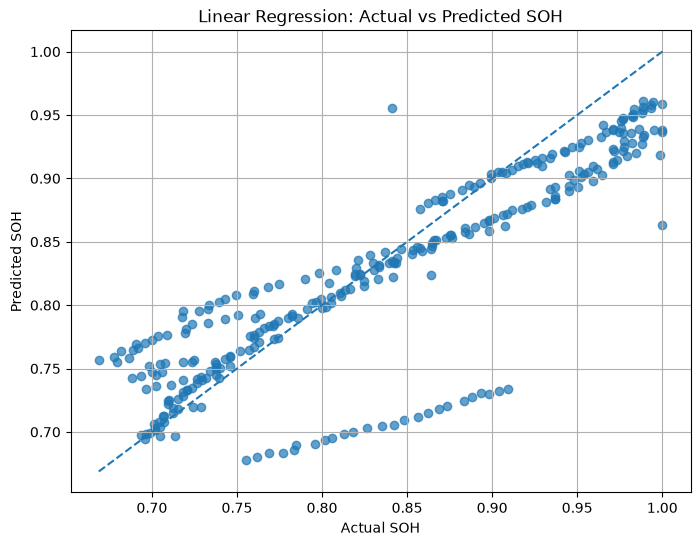

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")
plt.title("Linear Regression: Actual vs Predicted SOH")

plt.grid(True)
plt.show()

In [22]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        random_state=42
    ),

    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.01)
    )
}

print("Four regression models are ready!")

Four regression models are ready!


In [23]:
results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

MODEL COMPARISON
            Model    MAE   RMSE     R2
              SVR 0.0203 0.0258 0.9314
    Random Forest 0.0235 0.0278 0.9207
    Decision Tree 0.0320 0.0399 0.8362
Linear Regression 0.0366 0.0518 0.7248


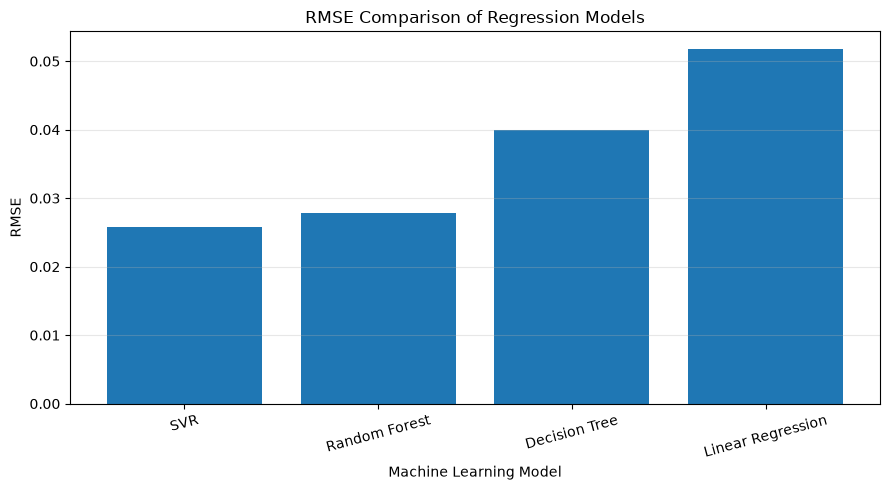

In [24]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["RMSE"]
)

plt.ylabel("RMSE")
plt.xlabel("Machine Learning Model")
plt.title("RMSE Comparison of Regression Models")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
best_model = trained_models["SVR"]

svr_predictions = best_model.predict(X_test)

prediction_results = test_df[
    ["battery_id", "cycle", "soh"]
].copy()

prediction_results["predicted_soh"] = svr_predictions

prediction_results["absolute_error"] = abs(
    prediction_results["soh"]
    - prediction_results["predicted_soh"]
)

print("Sample predictions:")
print(prediction_results.head(15).round(4))

print("\nLargest prediction errors:")
print(
    prediction_results
    .sort_values("absolute_error", ascending=False)
    .head(10)
    .round(4)
)

Sample predictions:
   battery_id  cycle     soh  predicted_soh  absolute_error
0       B0005      1  1.0000         1.0059          0.0059
1       B0005      2  0.9946         1.0017          0.0072
2       B0005      3  0.9886         0.9948          0.0062
3       B0005      4  0.9936         0.9937          0.0001
4       B0005      5  0.9933         0.9899          0.0034
5       B0005      6  0.9888         0.9842          0.0046
6       B0005      7  0.9885         0.9840          0.0045
7       B0005      8  0.9835         0.9813          0.0021
8       B0005      9  0.9880         0.9790          0.0089
9       B0005     10  0.9828         0.9755          0.0073
10      B0005     11  0.9828         0.9723          0.0105
11      B0005     12  0.9823         0.9737          0.0085
12      B0005     13  0.9770         0.9714          0.0056
13      B0005     14  0.9768         0.9687          0.0081
14      B0005     15  0.9760         0.9672          0.0088

Largest prediction 

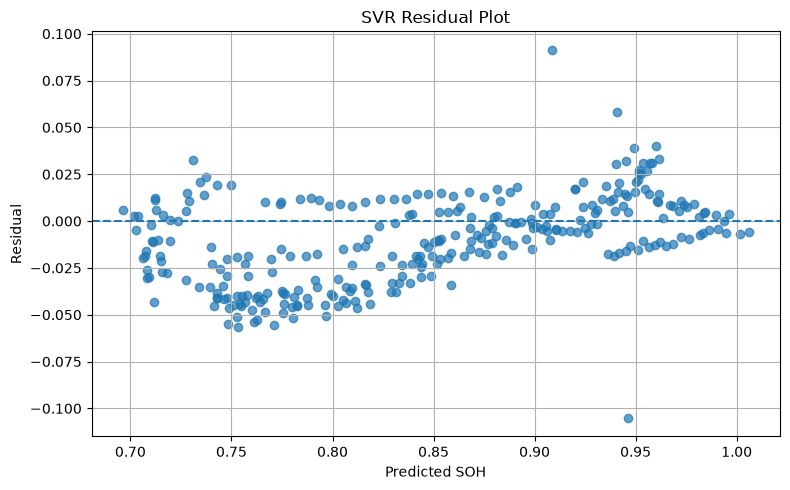

In [26]:
residuals = y_test - svr_predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    svr_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted SOH")
plt.ylabel("Residual")
plt.title("SVR Residual Plot")

plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.model_selection import GroupKFold, cross_validate

cv_df = eligible_df.copy()

X_cv = cv_df[features]
y_cv = cv_df[target]
groups = cv_df["battery_id"]

group_cv = GroupKFold(n_splits=5)

cv_models = {
    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.01)
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        random_state=42
    )
}

cv_results = []

for name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_cv,
        y_cv,
        groups=groups,
        cv=group_cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        }
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean(),
        "Mean R2": scores["test_r2"].mean(),
        "RMSE Std": scores["test_rmse"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

print("GROUP CROSS-VALIDATION RESULTS")
print(cv_results_df.round(4).to_string(index=False))

GROUP CROSS-VALIDATION RESULTS
        Model  Mean MAE  Mean RMSE  Mean R2  RMSE Std
          SVR    0.0351     0.0430   0.8030    0.0221
Random Forest    0.0399     0.0485   0.7619    0.0102


In [28]:
print("Capacity-SOH correlation:")
print(df[["capacity", "soh"]].corr())

print("\nSample capacity and SOH values:")
print(
    df[
        ["battery_id", "cycle", "capacity", "soh"]
    ].head(15).round(4)
)

print("\nCapacity divided by SOH:")
print(
    (df["capacity"] / df["soh"])
    .describe()
    .round(4)
)

Capacity-SOH correlation:
          capacity       soh
capacity  1.000000  0.643486
soh       0.643486  1.000000

Sample capacity and SOH values:
   battery_id  cycle  capacity     soh
0       B0005      1    1.8620  1.0000
1       B0005      2    1.8519  0.9946
2       B0005      3    1.8408  0.9886
3       B0005      4    1.8501  0.9936
4       B0005      5    1.8494  0.9933
5       B0005      6    1.8411  0.9888
6       B0005      7    1.8406  0.9885
7       B0005      8    1.8312  0.9835
8       B0005      9    1.8395  0.9880
9       B0005     10    1.8300  0.9828
10      B0005     11    1.8300  0.9828
11      B0005     12    1.8290  0.9823
12      B0005     13    1.8191  0.9770
13      B0005     14    1.8188  0.9768
14      B0005     15    1.8173  0.9760

Capacity divided by SOH:
count    1415.0000
mean        1.7684
std         0.2737
min         0.5625
25%         1.6929
50%         1.7982
75%         1.9187
max         2.3898
dtype: float64


In [29]:
error_by_battery = (
    prediction_results
    .groupby("battery_id")
    .agg(
        records=("absolute_error", "count"),
        mean_absolute_error=("absolute_error", "mean"),
        maximum_error=("absolute_error", "max")
    )
    .sort_values("mean_absolute_error", ascending=False)
)

print(error_by_battery.round(4))

            records  mean_absolute_error  maximum_error
battery_id                                             
B0005           168               0.0252         0.0580
B0047            69               0.0175         0.0915
B0043            66               0.0110         0.1052


In [30]:
from sklearn.model_selection import GroupKFold, cross_validate

group_cv = GroupKFold(n_splits=5)

svr_cv = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=0.01)
)

svr_scores = cross_validate(
    svr_cv,
    X_cv,
    y_cv,
    groups=groups,
    cv=group_cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    }
)

fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": -svr_scores["test_mae"],
    "RMSE": -svr_scores["test_rmse"],
    "R2": svr_scores["test_r2"]
})

print(fold_results.round(4).to_string(index=False))

 Fold    MAE   RMSE     R2
    1 0.0352 0.0427 0.7865
    2 0.0253 0.0299 0.8987
    3 0.0204 0.0245 0.9437
    4 0.0245 0.0320 0.8403
    5 0.0703 0.0856 0.5459


In [31]:
from sklearn.model_selection import GroupKFold

group_cv = GroupKFold(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(
    group_cv.split(X_cv, y_cv, groups=groups), start=1
):
    train_batteries = sorted(set(groups.iloc[train_idx]))
    val_batteries = sorted(set(groups.iloc[val_idx]))

    print(f"\nFOLD {fold}")
    print("Training batteries:", train_batteries)
    print("Validation batteries:", val_batteries)
    print("Training records:", len(train_idx))
    print("Validation records:", len(val_idx))


FOLD 1
Training batteries: ['B0005', 'B0006', 'B0018', 'B0042', 'B0043', 'B0044', 'B0045', 'B0047', 'B0048']
Validation batteries: ['B0007', 'B0046']
Training records: 894
Validation records: 237

FOLD 2
Training batteries: ['B0006', 'B0007', 'B0018', 'B0042', 'B0043', 'B0045', 'B0046', 'B0047', 'B0048']
Validation batteries: ['B0005', 'B0044']
Training records: 897
Validation records: 234

FOLD 3
Training batteries: ['B0005', 'B0007', 'B0018', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0048']
Validation batteries: ['B0006', 'B0047']
Training records: 907
Validation records: 224

FOLD 4
Training batteries: ['B0005', 'B0006', 'B0007', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0047']
Validation batteries: ['B0018', 'B0048']
Training records: 930
Validation records: 201

FOLD 5
Training batteries: ['B0005', 'B0006', 'B0007', 'B0018', 'B0044', 'B0046', 'B0047', 'B0048']
Validation batteries: ['B0042', 'B0043', 'B0045']
Training records: 896
Validation records: 235


In [32]:
import pandas as pd

fold_number = 5

train_idx, val_idx = list(
    group_cv.split(X_cv, y_cv, groups=groups)
)[fold_number - 1]

train_battery_ids = sorted(set(groups.iloc[train_idx]))
val_battery_ids = sorted(set(groups.iloc[val_idx]))

train_summary = (
    df[df["battery_id"].isin(train_battery_ids)]
    .groupby("battery_id")
    .agg(
        records=("soh", "count"),
        min_soh=("soh", "min"),
        mean_soh=("soh", "mean"),
        max_soh=("soh", "max")
    )
)

val_summary = (
    df[df["battery_id"].isin(val_battery_ids)]
    .groupby("battery_id")
    .agg(
        records=("soh", "count"),
        min_soh=("soh", "min"),
        mean_soh=("soh", "mean"),
        max_soh=("soh", "max")
    )
)

print("TRAINING BATTERIES")
print(train_summary.round(4))

print("\nVALIDATION BATTERIES — FOLD 5")
print(val_summary.round(4))

print("\nOVERALL TRAINING SOH RANGE:")
print(round(df[df["battery_id"].isin(train_battery_ids)]["soh"].min(), 4),
      "to",
      round(df[df["battery_id"].isin(train_battery_ids)]["soh"].max(), 4))

print("\nOVERALL VALIDATION SOH RANGE:")
print(round(df[df["battery_id"].isin(val_battery_ids)]["soh"].min(), 4),
      "to",
      round(df[df["battery_id"].isin(val_battery_ids)]["soh"].max(), 4))

TRAINING BATTERIES
            records  min_soh  mean_soh  max_soh
battery_id                                     
B0005           168   0.6934    0.8469   1.0001
B0006           155   0.6044    0.7727   1.0000
B0007           168   0.7425    0.8689   1.0000
B0018           132   0.7261    0.8438   1.0000
B0044            66   0.7404    0.8725   1.0000
B0046            69   0.6748    0.7605   1.0000
B0047            69   0.6688    0.7565   1.0000
B0048            69   0.6987    0.7841   1.0000

VALIDATION BATTERIES — FOLD 5
            records  min_soh  mean_soh  max_soh
battery_id                                     
B0042            99   0.6085    0.8184      1.0
B0043            66   0.7553    0.8870      1.0
B0045            70   0.6157    0.6905      1.0

OVERALL TRAINING SOH RANGE:
0.6044 to 1.0001

OVERALL VALIDATION SOH RANGE:
0.6085 to 1.0


In [33]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Recreate Fold 5
folds = list(group_cv.split(X_cv, y_cv, groups=groups))
train_idx, val_idx = folds[4]

X_train_fold = X_cv.iloc[train_idx]
X_val_fold = X_cv.iloc[val_idx]

y_train_fold = y_cv.iloc[train_idx]
y_val_fold = y_cv.iloc[val_idx]

# Train SVR on Fold 5 training batteries only
fold_model = clone(svr_cv)
fold_model.fit(X_train_fold, y_train_fold)

# Predict SOH for the unseen validation batteries
fold_predictions = fold_model.predict(X_val_fold)

# Collect actual and predicted values
fold_results = pd.DataFrame({
    "battery_id": groups.iloc[val_idx].to_numpy(),
    "actual_soh": y_val_fold.to_numpy(),
    "predicted_soh": fold_predictions
})

fold_results["absolute_error"] = (
    fold_results["actual_soh"] -
    fold_results["predicted_soh"]
).abs()

# Calculate metrics for each battery
battery_errors = (
    fold_results.groupby("battery_id")
    .apply(
        lambda g: pd.Series({
            "records": len(g),
            "MAE": mean_absolute_error(
                g["actual_soh"], g["predicted_soh"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    g["actual_soh"], g["predicted_soh"]
                )
            ),
            "R2": (
                r2_score(g["actual_soh"], g["predicted_soh"])
                if len(g) >= 2 else np.nan
            )
        }),
        include_groups=False
    )
)

print("FOLD 5 PERFORMANCE BY BATTERY")
print(battery_errors.round(4))

print("\nOVERALL FOLD 5 PERFORMANCE")
print("MAE:", round(
    mean_absolute_error(y_val_fold, fold_predictions), 4
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_val_fold, fold_predictions)), 4
))
print("R2:", round(
    r2_score(y_val_fold, fold_predictions), 4
))

FOLD 5 PERFORMANCE BY BATTERY
            records     MAE    RMSE      R2
battery_id                                 
B0042          99.0  0.0968  0.1099  0.3505
B0043          66.0  0.0187  0.0219  0.8628
B0045          70.0  0.0815  0.0841 -0.4181

OVERALL FOLD 5 PERFORMANCE
MAE: 0.0703
RMSE: 0.0856
R2: 0.5459


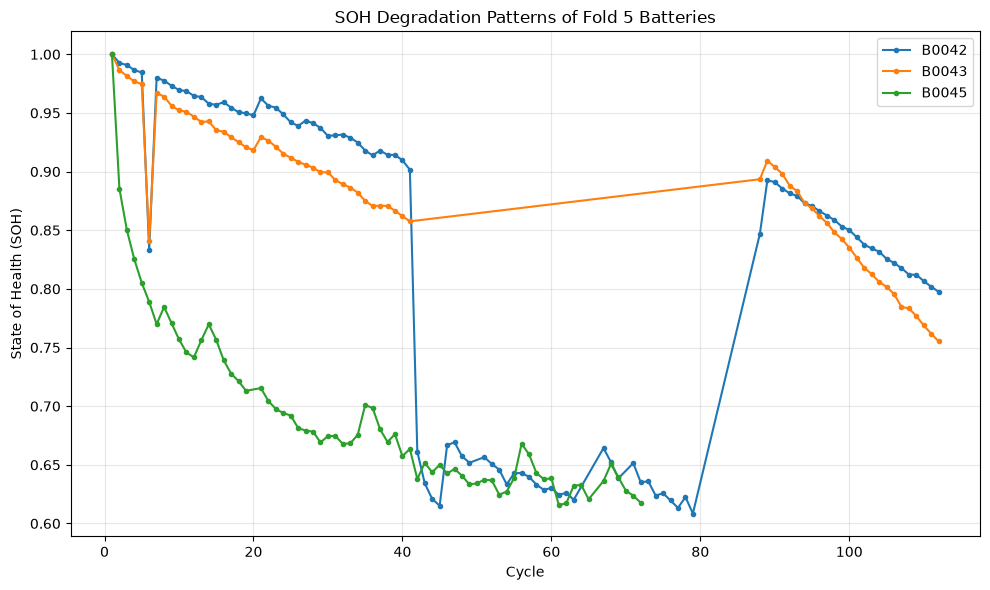

In [34]:
import matplotlib.pyplot as plt

batteries_to_check = ["B0042", "B0043", "B0045"]

plt.figure(figsize=(10, 6))

for battery in batteries_to_check:
    battery_data = (
        df[df["battery_id"] == battery]
        .sort_values("cycle")
    )

    plt.plot(
        battery_data["cycle"],
        battery_data["soh"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=battery
    )

plt.xlabel("Cycle")
plt.ylabel("State of Health (SOH)")
plt.title("SOH Degradation Patterns of Fold 5 Batteries")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
feature_summary = (
    df[df["battery_id"].isin(
        ["B0005", "B0006", "B0007", "B0018",
         "B0044", "B0046", "B0047", "B0048",
         "B0042", "B0043", "B0045"]
    )]
    .groupby("battery_id")
    .agg(
        mean_cycle=("cycle", "mean"),
        mean_voltage=("voltage", "mean"),
        mean_temperature=("temperature", "mean"),
        mean_soh=("soh", "mean")
    )
)

print(feature_summary.round(4))

            mean_cycle  mean_voltage  mean_temperature  mean_soh
battery_id                                                      
B0005          84.5000        3.5182           32.6960    0.8469
B0006          78.0000        3.4674           32.7017    0.7727
B0007          84.5000        3.5186           32.3406    0.8689
B0018          66.5000        3.5016           30.9266    0.8438
B0042          53.9899        3.1765           22.7201    0.8184
B0043          50.9242        3.4760           21.8805    0.8870
B0044          50.9242        3.4479           22.5505    0.8725
B0045          36.3143        3.3372            9.4322    0.6905
B0046          36.0580        3.3535            9.1742    0.7605
B0047          36.0580        3.4026            8.4959    0.7565
B0048          36.0580        3.4131            7.9966    0.7841


In [36]:
batteries_to_check = {
    "B0042": [40, 41, 42, 43, 44, 87, 88, 89, 90],
    "B0043": [4, 5, 6, 7, 8, 87, 88, 89, 90],
    "B0045": [1, 2, 3, 4, 5, 6, 7]
}

for battery, cycles in batteries_to_check.items():
    print(f"\n{'=' * 60}")
    print(f"Battery: {battery}")
    print("=" * 60)

    battery_data = (
        df[
            (df["battery_id"] == battery) &
            (df["cycle"].isin(cycles))
        ]
        .sort_values("cycle")
    )

    print(
        battery_data[
            ["battery_id", "cycle", "voltage",
             "temperature", "soh"]
        ].to_string(index=False)
    )


Battery: B0042
battery_id  cycle  voltage  temperature      soh
     B0042     40 3.483960    30.590041 0.909670
     B0042     41 3.476806    30.219231 0.901620
     B0042     42 2.705276    24.183403 0.661264
     B0042     43 2.679525    23.826987 0.634208
     B0042     44 2.679116    23.779750 0.620922
     B0042     88 3.377142     8.324354 0.847108
     B0042     89 3.425013     8.088311 0.892618
     B0042     90 3.427812     8.108636 0.891008

Battery: B0043
battery_id  cycle  voltage  temperature      soh
     B0043      4 3.496866    30.008101 0.976830
     B0043      5 3.501376    30.400639 0.974674
     B0043      6 3.579340    29.923858 0.840848
     B0043      7 3.508375    30.599878 0.966882
     B0043      8 3.503253    30.281715 0.964001
     B0043     88 3.469391     7.784855 0.893481
     B0043     89 3.488156     7.684550 0.909399
     B0043     90 3.488348     7.720356 0.903745

Battery: B0045
battery_id  cycle  voltage  temperature      soh
     B0045      1 3.3

In [37]:
batteries_to_check = ["B0042", "B0043", "B0045"]

for battery in batteries_to_check:
    battery_data = (
        df[df["battery_id"] == battery]
        .sort_values("cycle")
        .copy()
    )

    battery_data["cycle_gap"] = battery_data["cycle"].diff()
    battery_data["soh_change"] = battery_data["soh"].diff()

    print(f"\n{'=' * 55}")
    print(f"Battery: {battery}")
    print("=" * 55)

    print(
        battery_data.loc[
            battery_data["soh_change"].abs() > 0.05,
            ["cycle", "cycle_gap", "voltage",
             "temperature", "soh", "soh_change"]
        ].to_string(index=False)
    )


Battery: B0042
 cycle  cycle_gap  voltage  temperature      soh  soh_change
     6        1.0 3.581392    29.449407 0.833241   -0.151256
     7        1.0 3.511927    30.133153 0.980128    0.146887
    42        1.0 2.705276    24.183403 0.661264   -0.240356
    46        1.0 2.691575    24.093822 0.666666    0.051506
    88        9.0 3.377142     8.324354 0.847108    0.238626

Battery: B0043
 cycle  cycle_gap  voltage  temperature      soh  soh_change
     6        1.0 3.579340    29.923858 0.840848   -0.133826
     7        1.0 3.508375    30.599878 0.966882    0.126034

Battery: B0045
 cycle  cycle_gap  voltage  temperature      soh  soh_change
     2        1.0 3.326159      9.50161 0.885479   -0.114521


In [38]:
import pandas as pd

anomaly_df = df.sort_values(
    ["battery_id", "cycle"]
).copy()

anomaly_df["cycle_gap"] = (
    anomaly_df.groupby("battery_id")["cycle"].diff()
)

anomaly_df["soh_change"] = (
    anomaly_df.groupby("battery_id")["soh"].diff()
)

anomaly_df["voltage_change"] = (
    anomaly_df.groupby("battery_id")["voltage"].diff()
)

anomaly_df["temperature_change"] = (
    anomaly_df.groupby("battery_id")["temperature"].diff()
)

large_changes = anomaly_df[
    anomaly_df["soh_change"].abs() > 0.05
].copy()

print("Total records:", len(df))
print("Records with absolute SOH change > 0.05:", len(large_changes))

print("\nLargest SOH changes:")
print(
    large_changes[
        [
            "battery_id",
            "cycle",
            "cycle_gap",
            "soh_change",
            "voltage_change",
            "temperature_change"
        ]
    ]
    .sort_values("soh_change", key=abs, ascending=False)
    .head(25)
    .round(4)
    .to_string(index=False)
)

Total records: 1415
Records with absolute SOH change > 0.05: 44

Largest SOH changes:
battery_id  cycle  cycle_gap  soh_change  voltage_change  temperature_change
     B0050     15       14.0     -0.3388          0.1421             -1.9428
     B0033    145      143.0     -0.2751          0.0419             -0.5315
     B0042     42        1.0     -0.2404         -0.7715             -6.0358
     B0042     88        9.0      0.2386          0.8471            -17.2766
     B0026      6        1.0     -0.2029         -0.1288             -1.2561
     B0040     47       46.0     -0.1695          0.2806             15.9436
     B0042      6        1.0     -0.1513          0.0772             -0.4030
     B0042      7        1.0      0.1469         -0.0695              0.6837
     B0026      8        2.0      0.1379          0.1278              1.1652
     B0043      6        1.0     -0.1338          0.0780             -0.4768
     B0043      7        1.0      0.1260         -0.0710           

In [39]:
print("SOH range:")
print(df["soh"].agg(["min", "mean", "max"]).round(4))

print("\nNumber of records in different SOH ranges:")
print(
    pd.cut(
        df["soh"],
        bins=[-float("inf"), 0.60, 0.70, 0.80, 0.90, 1.00, float("inf")],
        labels=[
            "Below 0.60",
            "0.60–0.70",
            "0.70–0.80",
            "0.80–0.90",
            "0.90–1.00",
            "Above 1.00"
        ]
    )
    .value_counts(sort=False)
)

SOH range:
min     0.6044
mean    0.8490
max     1.0485
Name: soh, dtype: float64

Number of records in different SOH ranges:
soh
Below 0.60      0
0.60–0.70     166
0.70–0.80     383
0.80–0.90     313
0.90–1.00     429
Above 1.00    124
Name: count, dtype: int64


In [40]:
consecutive_changes = large_changes[
    large_changes["cycle_gap"] == 1
].copy()

gap_changes = large_changes[
    large_changes["cycle_gap"] > 1
].copy()

print("Large SOH changes across consecutive cycles:",
      len(consecutive_changes))

print("Large SOH changes across cycle gaps:",
      len(gap_changes))

print("\nLarge changes across consecutive cycles:")
print(
    consecutive_changes[
        [
            "battery_id",
            "cycle",
            "soh_change",
            "voltage_change",
            "temperature_change"
        ]
    ]
    .sort_values("soh_change", key=abs, ascending=False)
    .round(4)
    .to_string(index=False)
)

print("\nLarge changes across cycle gaps:")
print(
    gap_changes[
        [
            "battery_id",
            "cycle",
            "cycle_gap",
            "soh_change"
        ]
    ]
    .sort_values("soh_change", key=abs, ascending=False)
    .round(4)
    .to_string(index=False)
)

Large SOH changes across consecutive cycles: 29
Large SOH changes across cycle gaps: 15

Large changes across consecutive cycles:
battery_id  cycle  soh_change  voltage_change  temperature_change
     B0042     42     -0.2404         -0.7715             -6.0358
     B0026      6     -0.2029         -0.1288             -1.2561
     B0042      6     -0.1513          0.0772             -0.4030
     B0042      7      0.1469         -0.0695              0.6837
     B0043      6     -0.1338          0.0780             -0.4768
     B0043      7      0.1260         -0.0710              0.6760
     B0046      2     -0.1224         -0.0157             -0.1638
     B0045      2     -0.1145         -0.0050             -0.0493
     B0044      6     -0.1056          0.0613             -0.4868
     B0044      7      0.1003         -0.0565              0.6182
     B0026      9      0.0968         -0.0114              0.0084
     B0048      2     -0.0930         -0.0091              0.0729
     B0047  

In [41]:
high_soh = df[df["soh"] > 1.00].copy()

print("Records with SOH > 1.00:", len(high_soh))

print("\nNumber of records above 1.00 per battery:")
print(
    high_soh.groupby("battery_id")
    .size()
    .sort_values(ascending=False)
    .to_string()
)

print("\nFirst 20 records with SOH > 1.00:")
print(
    high_soh[
        ["battery_id", "cycle", "voltage", "temperature", "soh"]
    ]
    .sort_values(["battery_id", "cycle"])
    .head(20)
    .round(4)
    .to_string(index=False)
)

Records with SOH > 1.00: 124

Number of records above 1.00 per battery:
battery_id
B0053    29
B0031    20
B0032    17
B0029    16
B0030    15
B0027     7
B0028     7
B0026     5
B0025     3
B0039     2
B0049     2
B0005     1

First 20 records with SOH > 1.00:
battery_id  cycle  voltage  temperature    soh
     B0005     21   3.5598      32.6225 1.0001
     B0025      2   3.3881      33.0692 1.0398
     B0025      3   3.3894      33.3549 1.0450
     B0025     12   3.4250      32.9295 1.0457
     B0026      9   3.4077      32.7258 1.0223
     B0026     13   3.4260      33.0648 1.0169
     B0026     17   3.3353      33.3323 1.0152
     B0026     20   3.4031      33.3348 1.0339
     B0026     25   3.4056      32.5213 1.0480
     B0027      6   3.3871      34.4338 1.0139
     B0027     10   3.3898      34.6148 1.0396
     B0027     12   3.3995      34.3269 1.0166
     B0027     13   3.3805      34.6064 1.0436
     B0027     14   3.4101      34.6651 1.0049
     B0027     16   3.4008      3

In [42]:
from pathlib import Path

project_path = Path.cwd()

print("Current notebook directory:")
print(project_path)

print("\nFiles available in this directory:")

for file in sorted(project_path.iterdir()):
    if file.is_file():
        print(file.name)

Current notebook directory:
/Users/dimpusritulyauppalapati/Battery_SOH_Prediction

Files available in this directory:
    battery_soh_prediction.ipynb
battery_cycle_level_dataset_CLEAN_FINAL.csv


In [43]:
print("SOH and capacity summary:")

print(
    df[["capacity", "soh"]]
    .describe()
    .round(4)
)

print("\nCorrelation between capacity and SOH:")

print(
    df[["capacity", "soh"]]
    .corr()
    .round(4)
)

print("\nCapacity divided by SOH:")

capacity_soh_ratio = df["capacity"] / df["soh"]

print(capacity_soh_ratio.describe().round(4))

SOH and capacity summary:
        capacity        soh
count  1415.0000  1415.0000
mean      1.5012     0.8490
std       0.3170     0.1192
min       0.5201     0.6044
25%       1.3216     0.7508
50%       1.5041     0.8504
75%       1.7090     0.9612
max       2.4990     1.0485

Correlation between capacity and SOH:
          capacity     soh
capacity    1.0000  0.6435
soh         0.6435  1.0000

Capacity divided by SOH:
count    1415.0000
mean        1.7684
std         0.2737
min         0.5625
25%         1.6929
50%         1.7982
75%         1.9187
max         2.3898
dtype: float64


In [44]:
battery_relationships = (
    df.groupby("battery_id")
    .agg(
        records=("soh", "size"),
        capacity_min=("capacity", "min"),
        capacity_max=("capacity", "max"),
        soh_min=("soh", "min"),
        soh_max=("soh", "max"),
        capacity_soh_corr=(
            "capacity",
            lambda x: x.corr(
                df.loc[x.index, "soh"]
            )
        )
    )
)

print(battery_relationships.round(4).to_string())

            records  capacity_min  capacity_max  soh_min  soh_max  capacity_soh_corr
battery_id                                                                          
B0005           168        1.2911        1.8621   0.6934   1.0001                1.0
B0006           155        1.2460        2.0614   0.6044   1.0000                1.0
B0007           168        1.4247        1.9187   0.7425   1.0000                1.0
B0018           132        1.3526        1.8629   0.7261   1.0000                1.0
B0025             5        2.3688        2.4990   0.9912   1.0457                1.0
B0026            18        1.7855        2.3761   0.7876   1.0480                1.0
B0027            14        1.9913        2.2437   0.9262   1.0436                1.0
B0028            27        1.9581        2.2846   0.8878   1.0358                1.0
B0029            32        1.6551        1.8235   0.9476   1.0440                1.0
B0030            34        1.5942        1.7741   0.9421   1.0484

/Users/dimpusritulyauppalapati/Battery_SOH_Prediction/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3029: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/Users/dimpusritulyauppalapati/Battery_SOH_Prediction/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2902: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/dimpusritulyauppalapati/Battery_SOH_Prediction/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2902: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


In [45]:
feature_columns = ["cycle", "voltage", "temperature"]

duplicate_features = df[
    df.duplicated(subset=feature_columns, keep=False)
].sort_values(feature_columns)

print(
    "Records sharing identical cycle, voltage and temperature:",
    len(duplicate_features)
)

if not duplicate_features.empty:
    print(
        duplicate_features[
            ["battery_id", "cycle", "voltage",
             "temperature", "capacity", "soh"]
        ].head(20).to_string(index=False)
    )

Records sharing identical cycle, voltage and temperature: 0


In [46]:
import numpy as np
import pandas as pd

relationship_results = []

for battery, group in df.groupby("battery_id"):
    if len(group) < 2:
        continue

    capacity = group["capacity"].to_numpy()
    soh = group["soh"].to_numpy()

    slope, intercept = np.polyfit(capacity, soh, 1)

    predicted_soh = slope * capacity + intercept

    max_abs_error = np.max(
        np.abs(soh - predicted_soh)
    )

    relationship_results.append({
        "battery_id": battery,
        "records": len(group),
        "slope": slope,
        "intercept": intercept,
        "max_abs_error": max_abs_error
    })

relationship_df = pd.DataFrame(relationship_results)

print(
    relationship_df
    .sort_values("max_abs_error", ascending=False)
    .round(8)
    .to_string(index=False)
)

print("\nLargest deviation from a battery-specific linear relationship:")
print(relationship_df["max_abs_error"].max())

battery_id  records    slope  intercept  max_abs_error
     B0041       25 0.751252        0.0            0.0
     B0005      168 0.537064        0.0            0.0
     B0007      168 0.521198        0.0            0.0
     B0050        2 1.062368       -0.0            0.0
     B0026       18 0.441082       -0.0            0.0
     B0030       34 0.590940        0.0            0.0
     B0042       99 0.565241       -0.0            0.0
     B0043       66 0.577226       -0.0            0.0
     B0033        3 1.393719       -0.0            0.0
     B0046       69 0.556118       -0.0            0.0
     B0045       70 0.824399       -0.0            0.0
     B0044       66 0.591898       -0.0            0.0
     B0032       29 0.584639        0.0            0.0
     B0048       69 0.602349       -0.0            0.0
     B0031       21 0.590704        0.0            0.0
     B0029       32 0.572524       -0.0            0.0
     B0028       27 0.453409        0.0            0.0
     B0027

In [47]:
variation_results = []

for battery, group in df.groupby("battery_id"):

    if len(group) < 2:
        continue

    variation_results.append({
        "battery_id": battery,
        "records": len(group),
        "capacity_min": group["capacity"].min(),
        "capacity_max": group["capacity"].max(),
        "capacity_std": group["capacity"].std(),
        "soh_min": group["soh"].min(),
        "soh_max": group["soh"].max(),
        "soh_std": group["soh"].std()
    })

variation_df = pd.DataFrame(variation_results)

print(
    variation_df
    .sort_values("records", ascending=False)
    .round(6)
    .to_string(index=False)
)

battery_id  records  capacity_min  capacity_max  capacity_std  soh_min  soh_max  soh_std
     B0005      168      1.291135      1.862150      0.191341 0.693422 1.000093 0.102762
     B0007      168      1.424687      1.918658      0.160328 0.742543 1.000000 0.083563
     B0006      155      1.245989      2.061365      0.237974 0.604449 1.000000 0.115445
     B0018      132      1.352595      1.862861      0.152788 0.726085 1.000000 0.082018
     B0042       99      1.076499      1.769158      0.242527 0.608481 1.000000 0.137086
     B0045       70      0.746906      1.213004      0.086280 0.615749 1.000000 0.071129
     B0048       69      1.159896      1.660166      0.099529 0.698663 1.000000 0.059951
     B0047       69      1.140907      1.705983      0.118767 0.668768 1.000000 0.069618
     B0046       69      1.213346      1.798180      0.116431 0.674763 1.000000 0.064749
     B0044       66      1.250849      1.689481      0.109780 0.740375 1.000000 0.064978
     B0043       66  

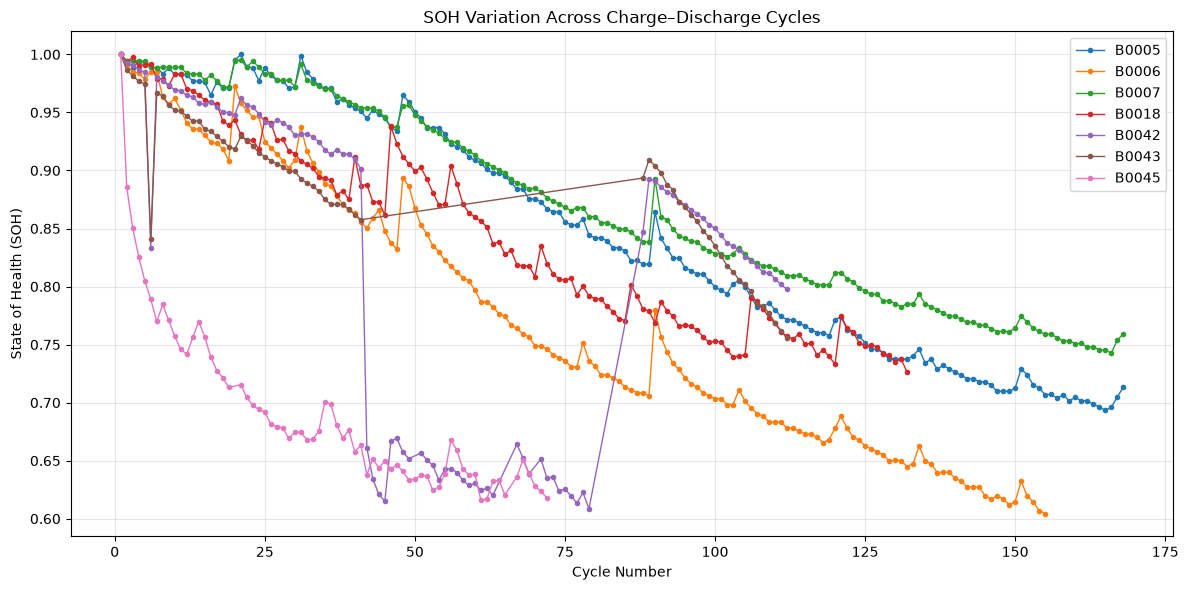

In [48]:
import matplotlib.pyplot as plt

selected_batteries = [
    "B0005",
    "B0006",
    "B0007",
    "B0018",
    "B0042",
    "B0043",
    "B0045"
]

plt.figure(figsize=(12, 6))

for battery in selected_batteries:
    battery_data = (
        df[df["battery_id"] == battery]
        .sort_values("cycle")
    )

    plt.plot(
        battery_data["cycle"],
        battery_data["soh"],
        marker="o",
        markersize=3,
        linewidth=1,
        label=battery
    )

plt.xlabel("Cycle Number")
plt.ylabel("State of Health (SOH)")
plt.title("SOH Variation Across Charge–Discharge Cycles")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [49]:
correlation_results = []

for battery, group in df.groupby("battery_id"):

    if len(group) < 3:
        continue

    correlation = group["cycle"].corr(group["soh"])

    correlation_results.append({
        "battery_id": battery,
        "records": len(group),
        "cycle_soh_correlation": correlation
    })

correlation_df = pd.DataFrame(correlation_results)

print(
    correlation_df
    .sort_values("cycle_soh_correlation")
    .round(4)
    .to_string(index=False)
)

print("\nOverall summary:")
print(
    correlation_df["cycle_soh_correlation"]
    .describe()
    .round(4)
)

battery_id  records  cycle_soh_correlation
     B0033        3                -0.9981
     B0007      168                -0.9886
     B0005      168                -0.9881
     B0006      155                -0.9785
     B0018      132                -0.9691
     B0041       25                -0.9141
     B0030       34                -0.9025
     B0046       69                -0.8889
     B0029       32                -0.8746
     B0044       66                -0.8683
     B0039       11                -0.8571
     B0047       69                -0.8565
     B0045       70                -0.8530
     B0043       66                -0.8341
     B0048       69                -0.8215
     B0032       29                -0.7867
     B0053       45                -0.5183
     B0042       99                -0.4350
     B0031       21                -0.3610
     B0049        8                -0.3269
     B0026       18                 0.3908
     B0028       27                 0.4050
     B0025 

In [50]:
import pandas as pd

batteries_to_check = [
    "B0025",
    "B0026",
    "B0027",
    "B0028",
    "B0031",
    "B0042",
    "B0049"
]

for battery in batteries_to_check:

    battery_data = (
        df[df["battery_id"] == battery]
        .sort_values("cycle")
        .copy()
    )

    battery_data["cycle_gap"] = (
        battery_data["cycle"].diff()
    )

    print(f"\n{'=' * 65}")
    print(f"Battery: {battery}")
    print(f"Number of records: {len(battery_data)}")
    print(f"Cycle-SOH correlation: "
          f"{battery_data['cycle'].corr(battery_data['soh']):.4f}")

    print(
        battery_data[
            [
                "cycle",
                "cycle_gap",
                "voltage",
                "temperature",
                "capacity",
                "soh"
            ]
        ].round(4).to_string(index=False)
    )


Battery: B0025
Number of records: 5
Cycle-SOH correlation: 0.4124
 cycle  cycle_gap  voltage  temperature  capacity    soh
     1        NaN   3.3894      33.3116    2.3898 1.0000
     2        1.0   3.3881      33.0692    2.4850 1.0398
     3        1.0   3.3894      33.3549    2.4974 1.0450
     4        1.0   3.4125      33.2881    2.3688 0.9912
    12        8.0   3.4250      32.9295    2.4990 1.0457

Battery: B0026
Number of records: 18
Cycle-SOH correlation: 0.3908
 cycle  cycle_gap  voltage  temperature  capacity    soh
     1        NaN   3.3937      32.8247    2.2672 1.0000
     2        1.0   3.4038      32.6629    2.2042 0.9722
     3        1.0   3.4312      32.7558    2.2278 0.9827
     4        1.0   3.4186      32.9933    2.1413 0.9445
     5        1.0   3.4201      32.8083    2.2456 0.9905
     6        1.0   3.2913      31.5522    1.7855 0.7876
     8        2.0   3.4191      32.7174    2.0982 0.9255
     9        1.0   3.4077      32.7258    2.3177 1.0223
    10    

In [51]:
print("Available modeling variables:")

for name in [
    "svr_model",
    "svr",
    "best_model",
    "X_test",
    "y_test",
    "X_train",
    "y_train",
    "X_cv",
    "y_cv",
    "features",
    "target",
    "eligible_df"
]:
    print(f"{name}: {'Exists' if name in globals() else 'Not found'}")


Available modeling variables:
svr_model: Not found
svr: Not found
best_model: Exists
X_test: Exists
y_test: Exists
X_train: Exists
y_train: Exists
X_cv: Exists
y_cv: Exists
features: Exists
target: Exists
eligible_df: Exists


In [52]:
print("Model type:", type(best_model))
print("Model details:")
print(best_model)

Model type: <class 'sklearn.pipeline.Pipeline'>
Model details:
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svr', SVR(C=10, epsilon=0.01))])


In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_test)

prediction_df = pd.DataFrame({
    "Actual_SOH": np.asarray(y_test),
    "Predicted_SOH": y_pred
})

prediction_df["Absolute_Error"] = np.abs(
    prediction_df["Actual_SOH"]
    - prediction_df["Predicted_SOH"]
)

print("First 15 predictions:")
print(
    prediction_df.head(15)
    .round(4)
    .to_string(index=False)
)

print("\nLargest prediction errors:")
print(
    prediction_df
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(4)
    .to_string(index=False)
)

print("\nPrediction error summary:")
print(
    prediction_df["Absolute_Error"]
    .describe()
    .round(4)
)

First 15 predictions:
 Actual_SOH  Predicted_SOH  Absolute_Error
     1.0000         1.0059          0.0059
     0.9946         1.0017          0.0072
     0.9886         0.9948          0.0062
     0.9936         0.9937          0.0001
     0.9933         0.9899          0.0034
     0.9888         0.9842          0.0046
     0.9885         0.9840          0.0045
     0.9835         0.9813          0.0021
     0.9880         0.9790          0.0089
     0.9828         0.9755          0.0073
     0.9828         0.9723          0.0105
     0.9823         0.9737          0.0085
     0.9770         0.9714          0.0056
     0.9768         0.9687          0.0081
     0.9760         0.9672          0.0088

Largest prediction errors:
 Actual_SOH  Predicted_SOH  Absolute_Error
     0.8408         0.9460          0.1052
     1.0000         0.9085          0.0915
     0.9989         0.9409          0.0580
     0.6967         0.7535          0.0568
     0.7154         0.7708          0.0554
    

In [54]:
# Add battery IDs to the prediction results

prediction_df = prediction_df.copy()

prediction_df["battery_id"] = (
    eligible_df.loc[X_test.index, "battery_id"].values
)

print("Prediction error by battery:\n")

battery_error_summary = (
    prediction_df
    .groupby("battery_id")
    .agg(
        Number_of_Records=("Absolute_Error", "count"),
        MAE=("Absolute_Error", "mean"),
        Maximum_Error=("Absolute_Error", "max")
    )
    .sort_values("MAE", ascending=False)
)

print(battery_error_summary.round(4))

Prediction error by battery:

            Number_of_Records     MAE  Maximum_Error
battery_id                                          
B0005                     168  0.0252         0.0580
B0047                      69  0.0175         0.0915
B0043                      66  0.0110         0.1052


In [55]:
# Display the 10 predictions with the largest errors

worst_predictions = (
    prediction_df
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .copy()
)

print("10 Worst Predictions:\n")

print(
    worst_predictions[
        [
            "battery_id",
            "Actual_SOH",
            "Predicted_SOH",
            "Absolute_Error"
        ]
    ]
    .round(4)
    .to_string(index=False)
)

10 Worst Predictions:

battery_id  Actual_SOH  Predicted_SOH  Absolute_Error
     B0043      0.8408         0.9460          0.1052
     B0047      1.0000         0.9085          0.0915
     B0005      0.9989         0.9409          0.0580
     B0047      0.6967         0.7535          0.0568
     B0005      0.7154         0.7708          0.0554
     B0005      0.6934         0.7485          0.0550
     B0005      0.7071         0.7610          0.0539
     B0005      0.7098         0.7626          0.0528
     B0005      0.7290         0.7805          0.0515
     B0005      0.7015         0.7526          0.0511


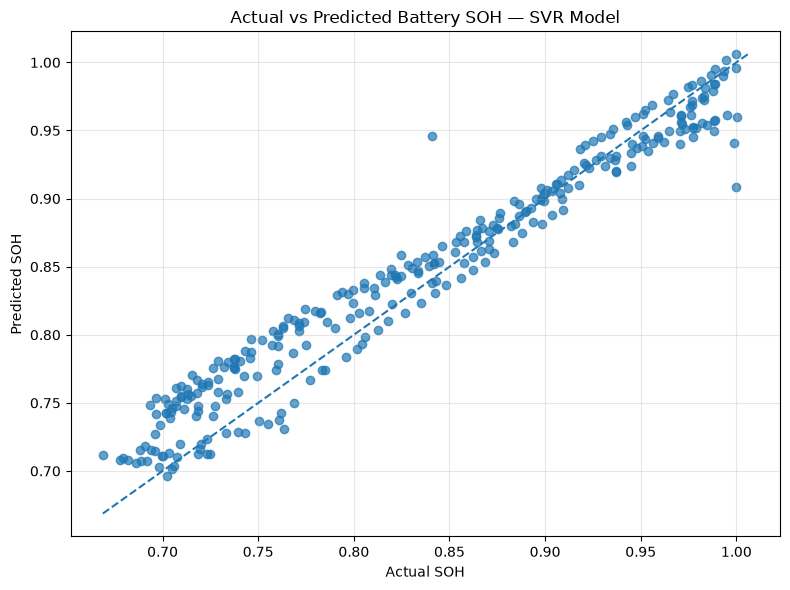

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    prediction_df["Actual_SOH"],
    prediction_df["Predicted_SOH"],
    alpha=0.7
)

# Perfect prediction reference line
min_value = min(
    prediction_df["Actual_SOH"].min(),
    prediction_df["Predicted_SOH"].min()
)

max_value = max(
    prediction_df["Actual_SOH"].max(),
    prediction_df["Predicted_SOH"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual SOH")
plt.ylabel("Predicted SOH")
plt.title("Actual vs Predicted Battery SOH — SVR Model")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
# Calculate signed prediction errors

prediction_df["Prediction_Error"] = (
    prediction_df["Predicted_SOH"]
    - prediction_df["Actual_SOH"]
)

# Summarize errors for each battery

signed_error_summary = (
    prediction_df
    .groupby("battery_id")
    .agg(
        Mean_Error=("Prediction_Error", "mean"),
        MAE=("Absolute_Error", "mean"),
        Maximum_Absolute_Error=("Absolute_Error", "max")
    )
    .sort_values("MAE", ascending=False)
)

print("Prediction Error Analysis by Battery:\n")
print(signed_error_summary.round(4))

Prediction Error Analysis by Battery:

            Mean_Error     MAE  Maximum_Absolute_Error
battery_id                                            
B0005           0.0148  0.0252                  0.0580
B0047           0.0100  0.0175                  0.0915
B0043           0.0000  0.0110                  0.1052


In [58]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
import pandas as pd
import numpy as np

# Define the models
models = {
    "Linear Regression": LinearRegression(),

    "SVR": Pipeline([
        ("standardscaler", StandardScaler()),
        ("svr", SVR(kernel="rbf", C=10, epsilon=0.01))
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        random_state=42
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    )
}

results = []

for name, model in models.items():

    # Train using the same training set
    model.fit(X_train, y_train)

    # Predict the test set
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

print("Final Test-Set Model Comparison:\n")
print(comparison_df.round(4).to_string(index=False))

Final Test-Set Model Comparison:

            Model    MAE   RMSE  R2 Score
              SVR 0.0203 0.0258    0.9314
    Random Forest 0.0235 0.0278    0.9207
    Decision Tree 0.0320 0.0399    0.8362
Linear Regression 0.0366 0.0518    0.7248


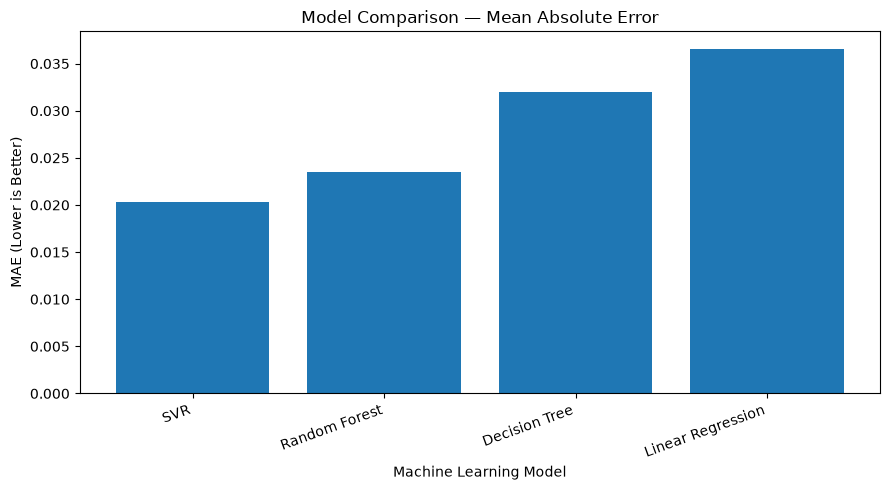

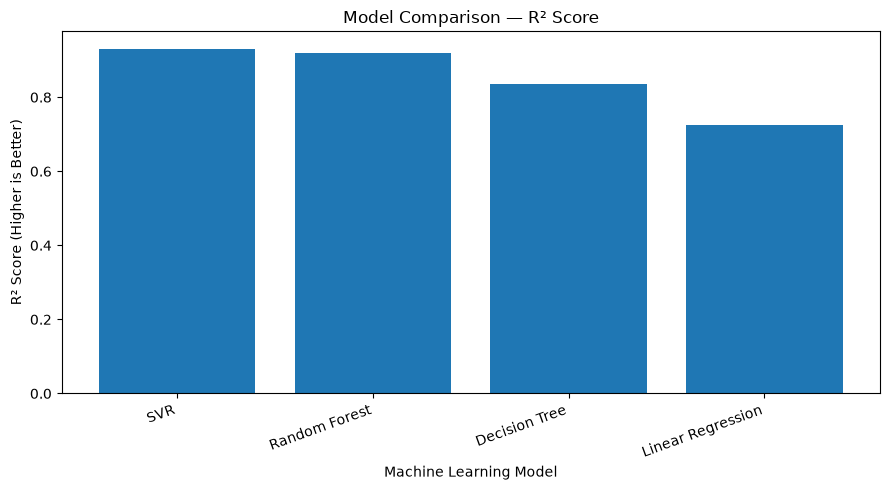

In [59]:
import matplotlib.pyplot as plt

# Plot MAE comparison
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["MAE"]
)

plt.title("Model Comparison — Mean Absolute Error")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE (Lower is Better)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()


# Plot R² comparison
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["R2 Score"]
)

plt.title("Model Comparison — R² Score")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score (Higher is Better)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

In [60]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate the selected SVR model on the held-out test set
svr_predictions = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, svr_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, svr_predictions))
test_r2 = r2_score(y_test, svr_predictions)

# Group cross-validation results recorded earlier
cv_mae = 0.0351
cv_rmse = 0.0430
cv_r2 = 0.8030

# Display evaluation summary
final_evaluation = pd.DataFrame({
    "Evaluation": [
        "Held-out test set",
        "5-fold battery-wise cross-validation"
    ],
    "MAE": [test_mae, cv_mae],
    "RMSE": [test_rmse, cv_rmse],
    "R2 Score": [test_r2, cv_r2]
})

print("FINAL SVR MODEL EVALUATION\n")
print(final_evaluation.round(4).to_string(index=False))

FINAL SVR MODEL EVALUATION

                          Evaluation    MAE   RMSE  R2 Score
                   Held-out test set 0.0203 0.0258    0.9314
5-fold battery-wise cross-validation 0.0351 0.0430    0.8030


In [61]:
import joblib
import os

# Create a folder for saved model files
os.makedirs("saved_models", exist_ok=True)

# Save the selected trained model
model_path = "saved_models/battery_soh_svr_model.pkl"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("File location:", os.path.abspath(model_path))


Model saved successfully!
File location: /Users/dimpusritulyauppalapati/Battery_SOH_Prediction/saved_models/battery_soh_svr_model.pkl


In [62]:
import joblib
import numpy as np

# Load the saved model
loaded_model = joblib.load(
    "saved_models/battery_soh_svr_model.pkl"
)

# Generate predictions using both models
original_predictions = best_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

# Verify that predictions match
if np.allclose(original_predictions, loaded_predictions):
    print("SUCCESS: Saved model loaded correctly!")
    print("Predictions match the original model.")
else:
    print("WARNING: Predictions do not match.")

print("\nSample predictions:")
for actual, predicted in zip(y_test[:5], loaded_predictions[:5]):
    print(f"Actual SOH: {actual:.4f} | Predicted SOH: {predicted:.4f}")

SUCCESS: Saved model loaded correctly!
Predictions match the original model.

Sample predictions:
Actual SOH: 1.0000 | Predicted SOH: 1.0059
Actual SOH: 0.9946 | Predicted SOH: 1.0017
Actual SOH: 0.9886 | Predicted SOH: 0.9948
Actual SOH: 0.9936 | Predicted SOH: 0.9937
Actual SOH: 0.9933 | Predicted SOH: 0.9899


In [63]:
# Verify the data used for model training and evaluation

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTraining feature columns:")
print(list(X_train.columns))

print("\nTest feature columns:")
print(list(X_test.columns))

print("\nUnique batteries in training data:")
print(
    eligible_df.loc[X_train.index, "battery_id"].nunique()
)

print("\nUnique batteries in test data:")
print(
    eligible_df.loc[X_test.index, "battery_id"].nunique()
)

# Verify that no battery occurs in both sets
train_batteries = set(
    eligible_df.loc[X_train.index, "battery_id"]
)

test_batteries = set(
    eligible_df.loc[X_test.index, "battery_id"]
)

print("\nShared batteries between train and test:")
print(train_batteries.intersection(test_batteries))

Training samples: 828
Test samples: 303

Training feature columns:
['cycle', 'voltage', 'temperature']

Test feature columns:
['cycle', 'voltage', 'temperature']

Unique batteries in training data:
8

Unique batteries in test data:
3

Shared batteries between train and test:
set()


In [64]:
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# Identify the battery associated with each training record
train_groups = eligible_df.loc[X_train.index, "battery_id"]

# Create the preprocessing and regression pipeline
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

# Define hyperparameter combinations to test
param_grid = {
    "svr__C": [1, 10, 50, 100],
    "svr__epsilon": [0.01, 0.05, 0.1],
    "svr__gamma": ["scale", 0.01, 0.1, 1]
}

# Keep each battery together within a cross-validation fold
group_cv = GroupKFold(n_splits=5)

# Configure the grid search
grid_search = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=group_cv,
    n_jobs=-1,
    return_train_score=True
)

# Tune using training data only
grid_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("HYPERPARAMETER TUNING RESULTS")
print("-" * 40)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(round(-grid_search.best_score_, 4))

print("\nNumber of Parameter Combinations Tested:")
print(len(grid_search.cv_results_["params"]))

HYPERPARAMETER TUNING RESULTS
----------------------------------------

Best Parameters:
{'svr__C': 1, 'svr__epsilon': 0.01, 'svr__gamma': 1}

Best Cross-Validation MAE:
0.0474

Number of Parameter Combinations Tested:
48


In [65]:
# Cell 63: Evaluate the tuned SVR model

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Get the best model configuration from GridSearchCV
tuned_model = clone(grid_search.best_estimator_)

# Train using only the training data
tuned_model.fit(X_train, y_train)

# Predict on the untouched test data
tuned_predictions = tuned_model.predict(X_test)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)

print("TUNED SVR MODEL PERFORMANCE")
print("-" * 40)
print("Best Parameters:", grid_search.best_params_)
print(f"Test MAE:  {tuned_mae:.4f}")
print(f"Test RMSE: {tuned_rmse:.4f}")
print(f"Test R²:   {tuned_r2:.4f}")

TUNED SVR MODEL PERFORMANCE
----------------------------------------
Best Parameters: {'svr__C': 1, 'svr__epsilon': 0.01, 'svr__gamma': 1}
Test MAE:  0.0218
Test RMSE: 0.0262
Test R²:   0.9293


In [66]:
# Cell 64: Compare all machine learning models

import pandas as pd

comparison_data = {
    "Model": [
        "Original SVR",
        "Tuned SVR",
        "Random Forest",
        "Decision Tree",
        "Linear Regression"
    ],
    "MAE": [
        0.0203,
        tuned_mae,
        0.0235,
        0.0320,
        0.0366
    ],
    "RMSE": [
        0.0258,
        tuned_rmse,
        0.0278,
        0.0399,
        0.0518
    ],
    "R2 Score": [
        0.9314,
        tuned_r2,
        0.9207,
        0.8362,
        0.7248
    ]
}

comparison_df = pd.DataFrame(comparison_data)

comparison_df = comparison_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

print("FINAL MODEL COMPARISON")
print("=" * 65)
display(comparison_df.round(4))

FINAL MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Original SVR,0.0203,0.0258,0.9314
1,Tuned SVR,0.0218,0.0262,0.9293
2,Random Forest,0.0235,0.0278,0.9207
3,Decision Tree,0.0320,0.0399,0.8362
4,Linear Regression,0.0366,0.0518,0.7248


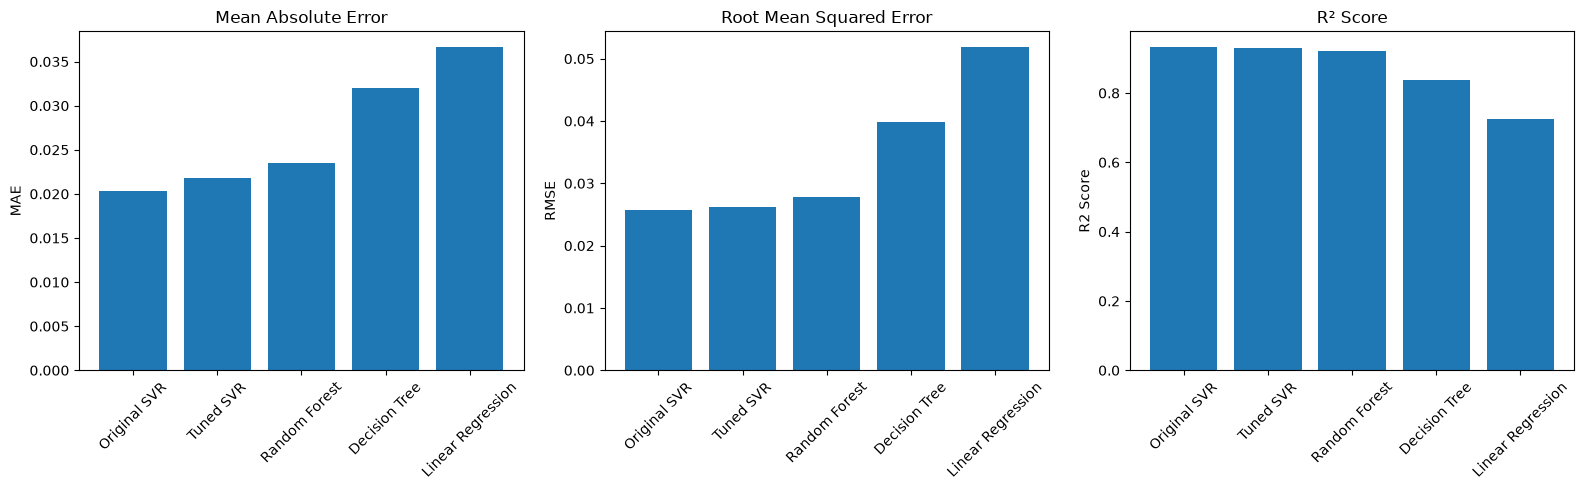

In [67]:
# Cell 65: Visualize model performance

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["MAE", "RMSE", "R2 Score"]
titles = ["Mean Absolute Error", "Root Mean Squared Error", "R² Score"]

for ax, metric, title in zip(axes, metrics, titles):
    ax.bar(comparison_df["Model"], comparison_df[metric])
    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [68]:
# Cell 66: Verify the final model candidate

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

final_model = best_model

final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

print("FINAL MODEL CANDIDATE")
print("=" * 40)
print("Model: Support Vector Regression (SVR)")
print("Features:", features)
print(f"Test MAE:  {final_mae:.4f}")
print(f"Test RMSE: {final_rmse:.4f}")
print(f"Test R²:   {final_r2:.4f}")

print("\nExpected test results:")
print("MAE approximately 0.0203")
print("RMSE approximately 0.0258")
print("R² approximately 0.9314")

FINAL MODEL CANDIDATE
Model: Support Vector Regression (SVR)
Features: ['cycle', 'voltage', 'temperature']
Test MAE:  0.0203
Test RMSE: 0.0258
Test R²:   0.9314

Expected test results:
MAE approximately 0.0203
RMSE approximately 0.0258
R² approximately 0.9314


In [69]:
# Cell 67: Save the final trained model

import os
import joblib

# Create a folder to store the final model
os.makedirs("saved_models", exist_ok=True)

# Save the trained model
model_path = "saved_models/final_battery_soh_model.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Model location:", os.path.abspath(model_path))

Model saved successfully!
Model location: /Users/dimpusritulyauppalapati/Battery_SOH_Prediction/saved_models/final_battery_soh_model.pkl


In [70]:
# Cell 68: Reload and verify the saved model

import joblib
import numpy as np

loaded_model = joblib.load(model_path)

# Generate predictions using the reloaded model
loaded_predictions = loaded_model.predict(X_test)

# Compare predictions
if np.allclose(final_predictions, loaded_predictions):
    print("SUCCESS: Model reloaded correctly!")
    print("Predictions match the original model.")
else:
    print("WARNING: Predictions do not match!")

print("\nSample predictions:")
for actual, predicted in zip(y_test.iloc[:5], loaded_predictions[:5]):
    print(f"Actual SOH: {actual:.4f} | Predicted SOH: {predicted:.4f}")

SUCCESS: Model reloaded correctly!
Predictions match the original model.

Sample predictions:
Actual SOH: 1.0000 | Predicted SOH: 1.0059
Actual SOH: 0.9946 | Predicted SOH: 1.0017
Actual SOH: 0.9886 | Predicted SOH: 0.9948
Actual SOH: 0.9936 | Predicted SOH: 0.9937
Actual SOH: 0.9933 | Predicted SOH: 0.9899


In [71]:
# Cell 69: Predict SOH for new battery measurements

import pandas as pd
import joblib

# Load the saved model without retraining
loaded_model = joblib.load(model_path)

# Example new input data
new_battery_data = pd.DataFrame({
    "cycle": [10, 50, 100],
    "voltage": [3.7, 3.6, 3.5],
    "temperature": [25, 30, 35]
})

# Predict SOH using the trained model
predicted_soh = loaded_model.predict(new_battery_data)

# Display predictions
results = new_battery_data.copy()
results["Predicted_SOH"] = predicted_soh

print("NEW BATTERY SOH PREDICTIONS")
print("=" * 45)
display(results.round(4))

NEW BATTERY SOH PREDICTIONS


,cycle,voltage,temperature,Predicted_SOH
0,10,3.7,25,0.8129
1,50,3.6,30,1.0475
2,100,3.5,35,0.8251


In [72]:
# Cell 70: Inspect feature ranges in the training dataset

print("TRAINING DATA FEATURE RANGES")
print("=" * 45)

for feature in features:
    print(f"\n{feature}")
    print(f"Minimum: {X_train[feature].min():.4f}")
    print(f"Maximum: {X_train[feature].max():.4f}")
    print(f"Mean:    {X_train[feature].mean():.4f}")
    print(f"Median:  {X_train[feature].median():.4f}")

print("\nNEW INPUT DATA")
display(new_battery_data)


TRAINING DATA FEATURE RANGES

cycle
Minimum: 1.0000
Maximum: 168.0000
Mean:    61.9420
Median:  55.0000

voltage
Minimum: 2.5300
Maximum: 3.5814
Mean:    3.4219
Median:  3.4593

temperature
Minimum: 7.7082
Maximum: 34.4866
Mean:    24.3562
Median:  30.9168

NEW INPUT DATA


,cycle,voltage,temperature
0,10,3.7,25
1,50,3.6,30
2,100,3.5,35


In [73]:
# Cell 71: Create new inputs within training-data ranges

import pandas as pd

new_battery_data = pd.DataFrame({
    "cycle": [10, 50, 100],
    "voltage": [3.50, 3.45, 3.40],
    "temperature": [25.0, 30.0, 32.0]
})

print("NEW INPUT DATA")
display(new_battery_data)

print("\nRANGE VALIDATION")
print("=" * 40)

for feature in features:
    minimum = X_train[feature].min()
    maximum = X_train[feature].max()

    valid = new_battery_data[feature].between(
        minimum, maximum
    ).all()

    print(
        f"{feature}: "
        f"{'PASS' if valid else 'FAIL'}"
    )
    

NEW INPUT DATA


,cycle,voltage,temperature
0,10,3.50,25.0
1,50,3.45,30.0
2,100,3.40,32.0



RANGE VALIDATION
cycle: PASS
voltage: PASS
temperature: PASS


In [74]:
# Cell 72: Predict SOH using the saved model

import joblib
import pandas as pd

# Load the saved model
loaded_model = joblib.load(model_path)

# Generate predictions without retraining
predictions = loaded_model.predict(new_battery_data)

# Display the results
prediction_results = new_battery_data.copy()
prediction_results["Predicted_SOH"] = predictions

print("BATTERY SOH PREDICTION RESULTS")
print("=" * 45)
display(prediction_results.round(4))

print("\nModel used: Saved SVR Pipeline")
print("Retraining performed: No")

BATTERY SOH PREDICTION RESULTS


,cycle,voltage,temperature,Predicted_SOH
0,10,3.50,25.0,0.9500
1,50,3.45,30.0,0.8135
2,100,3.40,32.0,0.6763



Model used: Saved SVR Pipeline
Retraining performed: No


In [75]:
# Cell 73: Investigate how SOH relates to capacity

import pandas as pd
import numpy as np

print("CAPACITY AND SOH RELATIONSHIP")
print("=" * 45)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nCapacity statistics:")
print(df["capacity"].describe())

print("\nSOH statistics:")
print(df["soh"].describe())

print("\nOverall correlation:")
print(df[["capacity", "soh"]].corr().round(4))

print("\nSample records:")
display(df[["battery_id", "cycle", "capacity", "soh"]].head(10))


CAPACITY AND SOH RELATIONSHIP

Dataset columns:
['battery_id', 'cycle', 'voltage', 'temperature', 'capacity', 'soh', 'rul']

Capacity statistics:
count    1415.000000
mean        1.501191
std         0.316995
min         0.520105
25%         1.321640
50%         1.504115
75%         1.709022
max         2.498996
Name: capacity, dtype: float64

SOH statistics:
count    1415.000000
mean        0.849014
std         0.119219
min         0.604449
25%         0.750777
50%         0.850350
75%         0.961174
max         1.048527
Name: soh, dtype: float64

Overall correlation:
          capacity     soh
capacity    1.0000  0.6435
soh         0.6435  1.0000

Sample records:


,battery_id,cycle,capacity,soh
0,B0005,1,1.861976,1.000000
1,B0005,2,1.851862,0.994568
2,B0005,3,1.840808,0.988631
3,B0005,4,1.850058,0.993599
4,B0005,5,1.849432,0.993263
5,B0005,6,1.841138,0.988808
6,B0005,7,1.840621,0.988531
7,B0005,8,1.831164,0.983452
8,B0005,9,1.839546,0.987953
9,B0005,10,1.830019,0.982837


In [76]:
# Cell 74: Analyze capacity-SOH relationships by battery

import pandas as pd

battery_relationship = (
    df.groupby("battery_id")
    .apply(
        lambda group: pd.Series({
            "Records": len(group),
            "Capacity_SOH_Correlation": (
                group["capacity"].corr(group["soh"])
                if group["capacity"].nunique() > 1
                and group["soh"].nunique() > 1
                else float("nan")
            ),
            "Mean_Capacity": group["capacity"].mean(),
            "Mean_SOH": group["soh"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

print("CAPACITY-SOH RELATIONSHIP BY BATTERY")
print("=" * 55)

display(battery_relationship.round(4))

print("\nAverage within-battery correlation:")
print(
    round(
        battery_relationship["Capacity_SOH_Correlation"].mean(),
        4
    )
)

CAPACITY-SOH RELATIONSHIP BY BATTERY


,battery_id,Records,Capacity_SOH_Correlation,Mean_Capacity,Mean_SOH
0,B0005,168.0,1.0,1.5769,0.8469
1,B0006,155.0,1.0,1.5929,0.7727
2,B0007,168.0,1.0,1.6671,0.8689
3,B0018,132.0,1.0,1.5719,0.8438
4,B0025,5.0,1.0,2.4480,1.0244
5,B0026,18.0,1.0,2.2118,0.9756
6,B0027,14.0,1.0,2.1442,0.9973
7,B0028,27.0,1.0,2.1345,0.9678
8,B0029,32.0,1.0,1.7465,0.9999
9,B0030,34.0,1.0,1.6843,0.9953



Average within-battery correlation:
1.0


In [77]:
# Cell 75: Investigate the linear relationship between capacity and SOH

from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

relationship_results = []

for battery_id, group in df.groupby("battery_id"):

    if len(group) < 3:
        continue

    X_capacity = group[["capacity"]]
    y_soh = group["soh"]

    model = LinearRegression()
    model.fit(X_capacity, y_soh)

    predicted_soh = model.predict(X_capacity)

    max_error = np.max(
        np.abs(y_soh.to_numpy() - predicted_soh)
    )

    relationship_results.append({
        "battery_id": battery_id,
        "records": len(group),
        "slope": model.coef_[0],
        "intercept": model.intercept_,
        "max_absolute_error": max_error,
        "r_squared": model.score(X_capacity, y_soh)
    })

relationship_df = pd.DataFrame(relationship_results)

print("LINEAR RELATIONSHIP BETWEEN CAPACITY AND SOH")
print("=" * 65)

display(relationship_df.round(8))

print("\nMaximum absolute error across batteries:")
print(relationship_df["max_absolute_error"].max())

LINEAR RELATIONSHIP BETWEEN CAPACITY AND SOH


,battery_id,records,slope,intercept,max_absolute_error,r_squared
0,B0005,168,0.537064,0.0,0.0,1.0
1,B0006,155,0.485115,-0.0,0.0,1.0
2,B0007,168,0.521198,0.0,0.0,1.0
3,B0018,132,0.536809,0.0,0.0,1.0
4,B0025,5,0.418448,-0.0,0.0,1.0
5,B0026,18,0.441082,-0.0,0.0,1.0
6,B0027,14,0.465112,0.0,0.0,1.0
7,B0028,27,0.453409,0.0,0.0,1.0
8,B0029,32,0.572524,-0.0,0.0,1.0
9,B0030,34,0.590940,0.0,0.0,1.0



Maximum absolute error across batteries:
4.440892098500626e-16


In [78]:
# Cell 76: Final model verification

import os
import joblib
import numpy as np
import pandas as pd

model_path = "saved_models/final_battery_soh_model.pkl"

# Check whether the saved model exists
assert os.path.exists(model_path), "Saved model file not found!"

# Load the saved model
loaded_model = joblib.load(model_path)

# Generate predictions using the loaded model
saved_model_predictions = loaded_model.predict(X_test)

# Compare with the original model's predictions
original_predictions = best_model.predict(X_test)

predictions_match = np.allclose(
    saved_model_predictions,
    original_predictions
)

print("FINAL MODEL VERIFICATION")
print("=" * 40)
print("Saved model exists:", os.path.exists(model_path))
print("Predictions match:", predictions_match)
print("Number of test predictions:", len(saved_model_predictions))

print("\nFinal test performance:")
print("MAE:", round(float(np.mean(
    np.abs(y_test.to_numpy() - saved_model_predictions)
)), 4))

print("RMSE:", round(float(np.sqrt(
    np.mean((y_test.to_numpy() - saved_model_predictions) ** 2)
)), 4))

print("\nModel verification completed!")

FINAL MODEL VERIFICATION
Saved model exists: True
Predictions match: True
Number of test predictions: 303

Final test performance:
MAE: 0.0203
RMSE: 0.0258

Model verification completed!
